# Beyond: the UF as its own currency and a test that catches a behavioural assumption changed at a limit breach

**Question:** does treating the UF as a currency of its own change the Annex 1 measures of a bank on a peso and UF balance sheet by more than the rounding of a method (BS-7), and does the breach test tell a behavioural parameter changed while a limit is breached from one held fixed or changed with no breach (BS-8)?

- **Level:** 4, Beyond the state of the art
- **Prerequisites:** notebooks 01 to 07 of this topic
- **Reading time:** about 60 minutes

## Objectives

By the end of this notebook you can:

- state the two claims of this topic, BS-7 (the UF as its own currency in IRRBB) and BS-8 (a test that flags a behavioural assumption changed at a limit breach), the committed evidence for each, the practice each goes beyond, and the limit of each claim;
- show, with the engine, what a single-currency treatment of the UF would lose compared with Annex 1 (sizes, floor, offset and charge);
- run the breach test on controlled histories and on the committed parameters, and say what it discriminates and what it does not;
- say what a validator does with a red result of this test.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.irrbb import eve_nii, shocks, slotting
from riskvalidation.validation import irrbb as rv_irrbb

for name in ("riskvalidation", "numpy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
matplotlib 3.11.2


## Data

Two cases feed the two claims.

- **BS-7** reads case C15, the **synthetic** Banco Andino on a CLP and UF balance sheet at 2026-09-03, in four of its six variants: `short-uf`, `long-uf`, `offset-on-off` and `floors-active`. The balance-sheet aggregates are calibrated to the CMF system figures of August 2026 (https://www.cmfchile.cl/portal/estadisticas/617/articles-113863_recurso_1.pdf, public statistics, licence class `mirror-allowed`); the curves are the real yields of the Banco Central de Chile (BDE table F022, `mirror-allowed`). Money is in CLP millions.
- **BS-8** reads case C14, the bank that failed in March 2023, at the valuation dates 2021-Q4, 2022-Q2 and 2022-Q4: the FDIC call reports (https://api.fdic.gov/banks/financials) and the US Treasury par curve (https://home.treasury.gov/resource-center/data-chart-center/interest-rates), public-domain sources of the licence class `mirror-allowed`. The bank is **real in aggregate and synthetic in behaviour**: the share and the maturity of the stable deposits are stated by Contraste, and the replicating-portfolio maturity is fitted on the report history. Money is in USD thousands.

A positive delta EVE or delta NII is a loss in both.

- **Files read:** `data/derived/C15/short-uf.json`, `long-uf.json`, `offset-on-off.json` and `floors-active.json` (`outputs.legs`, `curves`, `eve`, `nii`, `floors`, `offset_rule`, `indexation_charge`, `thresholds`), `data/derived/C14/vd-2021-q4.json`, `vd-2022-q2.json` and `vd-2022-q4.json` (`outputs.nmd_segments`, `scenarios`) and `data/derived/C14/models-svb-2021-2022.json` (`fit.nmd_models`, `nmd_parameter_changes`).

The next cell loads the files and lists the variants and the valuation dates.

In [2]:
# Load the four C15 variants, the three C14 valuation dates and the C14 model document (three folders below the root)
ROOT = Path("../../..").resolve()
c15, c14 = ROOT / "data" / "derived" / "C15", ROOT / "data" / "derived" / "C14"
names = ("short-uf", "long-uf", "offset-on-off", "floors-active")
variants = {v: json.loads((c15 / f"{v}.json").read_text(encoding="utf-8")) for v in names}
quarters = ("2021-Q4", "2022-Q2", "2022-Q4")
docs = {q: json.loads((c14 / f"vd-{q.lower()}.json").read_text(encoding="utf-8")) for q in quarters}
fit = json.loads((c14 / "models-svb-2021-2022.json").read_text(encoding="utf-8"))["fit"]
MID = slotting.bucket_grid().midpoints
LANG = "en"  # the bilingual fields of the documents are read in this language
NAME = {True: "yes", False: "no"}
LIGHT = {"green": "green", "amber": "amber", "red": "red", "not_evaluated": "not evaluated"}
print("C15:", list(variants))
print("C14:", [d["outputs"]["valuation_date"] for d in docs.values()])

C15: ['short-uf', 'long-uf', 'offset-on-off', 'floors-active']
C14: ['2021-12-31', '2022-06-30', '2022-12-31']


## Method

The notebook states each claim, shows the evidence of the committed files with the engine, and shows a control or a counterfactual that makes the claim testable: for BS-7 the cost of not treating the UF as a currency, for BS-8 histories where the test must be green and where it must be red. Each claim ends with its limit. The claims and their evidence are stated in the SDD's section `## Beyond the state of the art`; the notebook does not state more than the SDD does.

- **BS-7.** The reajustabilidad risk of RAN 21-13 Annex 1 as a separate currency (the UR) with its own shocks, floor, the indexation charge (2.5 percent of the absolute net UF position) and the 50 percent offset of the peso delta against the UR delta. Evidence: `data/derived/C15/long-uf.json`, `floors-active.json`, `offset-on-off.json`.
- **BS-8.** The test `irrbb.behavioural_change_at_breach`, which turns a finding of the Federal Reserve's review of the failed bank into a validation test. Evidence: the committed parameters of `data/derived/C14/models-svb-2021-2022.json` and the breach flags of the three dates.

## State of the art

**For BS-7.** The Basel standard has 21 currencies in its shock table and a rule for aggregating them; it has no unit like the UF, an indexed unit of account whose value in the local currency follows inflation, and no currency of the local jurisdiction that is missing from the table gets a size (SRP31.90, Table 2; BCBS d578, https://www.bis.org/publications/202407-standards-recalibration-shocks-interest-rate-risk-banking-book.pdf). The Chilean regulator's Annex 1 of chapter 21-13 (https://www.cmfchile.cl/portal/principal/623/articles-29808_doc_pdf.pdf) fills that gap with the UR. The research found the Chilean approach described as "a genuine differentiator" (dossier 03, F.2) and found no public implementation of the Annex; that is a finding of the dossier's search and stays **UNVERIFIED** beyond it. The claim is regional, not global.

**For BS-8.** The Federal Reserve's review of Silicon Valley Bank states the practice as a finding: the bank "had breached its long-term IRR limits on and off since 2017" and "in April 2022 ... made counterintuitive modeling assumptions about the duration of deposits to address the limit breach rather than managing the actual risk" (https://www.federalreserve.gov/publications/files/svb-review-20230428.pdf; dossier 05, D.7). The research proposes the test ("a Contraste validation test should therefore flag any change in NMD behavioural parameters that coincides with a limit breach") and cites no tool that implements it.

The first cell below shows the first fact for BS-7 with the engine: the Basel table has no entry for the peso or for the UF, and the engine refuses a size for them instead of inventing one.

In [3]:
# The Basel table has no entry for the peso or the UF: the engine refuses a size; the Chilean table has both
for calibration in ("2016", "2024"):
    table = shocks.shock_table(calibration)
    has = [("no", "yes")[c in table] for c in ("CLP", "CLF")]
    print(calibration, "| currencies:", len(table), "| CLP:", has[0], "| CLF:", has[1])
for currency in ("CLP", "CLF"):
    try:
        shocks.shock_size(currency, "2024")
    except ValueError as error:
        print(currency, "the engine refuses a size:", type(error).__name__)
for currency in ("CLP", "CLF"):
    z = shocks.shock_size(currency, "cmf-annex1")
    print(f"{currency} cmf-annex1: {z.parallel_bp:.0f}/{z.short_bp:.0f}/{z.long_bp:.0f} bp | origin {z.origin}")

2016 | currencies: 21 | CLP: no | CLF: no
2024 | currencies: 21 | CLP: no | CLF: no
CLP the engine refuses a size: ValueError
CLF the engine refuses a size: ValueError
CLP cmf-annex1: 300/400/200 bp | origin cmf-annex1
CLF cmf-annex1: 200/250/150 bp | origin cmf-annex1


## Beyond the state of the art

### BS-7: the UF as its own currency

**What the claim adds.** Annex 1 of chapter 21-13 treats the reajustabilidad risk as a separate currency with its own shocks, its own floor, the indexation charge and the 50 percent offset; the engine implements it, and the committed C15 variants recompute from it. The first cell shows the separation in the committed documents: the sizes and the floor of each currency and the curve each one is discounted on. The second shows why the floor must be the currency's own: the UR curve is a real-rate curve, around 1.2 to 2.8 percent, and a downward shock of 200 bp pushes its short end below zero, where the peso floor of 0 percent would bind in nine bands and the UR floor of -2 percent in none.

EVE sizes (par/short/long) | NII size | floor | rate band 1 | rate band 19
CLP  300/400/200 | 300 | 0.00
    0.04499 | 0.05911
UR   200/250/150 | 300 | -0.02
    0.01205 | 0.02839


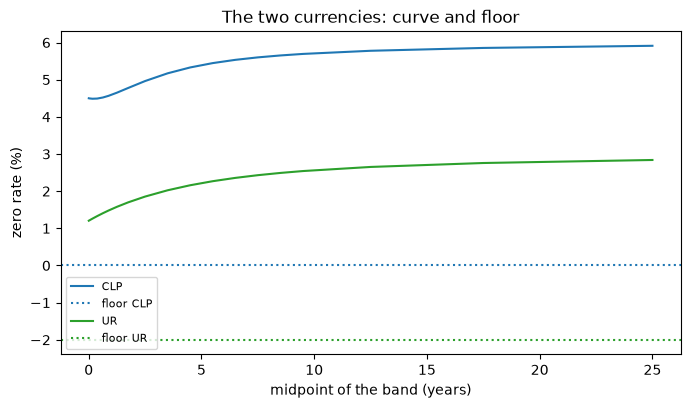

In [4]:
# The sizes, the floor and the curve of each currency in the committed documents, and the engine's size for each
out = variants["short-uf"]["outputs"]
rates = {"CLP": np.array(out["curves"]["clp"]["zero_rates_at_midpoints"])}
rates["UR"] = np.array(out["curves"]["ur"]["zero_rates_at_midpoints"])
floors = {"CLP": out["floors"]["other_floor"], "UR": out["floors"]["ur_floor"]}
print("EVE sizes (par/short/long) | NII size | floor | rate band 1 | rate band 19")
for committed in out["eve_shock_sizes"]:
    leg = "CLP" if committed["currency"] == "CLP" else "UR"
    nii = next(x["parallel_bp"] for x in out["nii_shock_sizes"] if x["currency"] == committed["currency"])
    z = shocks.shock_size(committed["currency"], "cmf-annex1")
    print(f"{leg:4s} {z.parallel_bp:.0f}/{z.short_bp:.0f}/{z.long_bp:.0f} | {nii:.0f} | {floors[leg]:.2f}")
    print(f"    {rates[leg][0]:.5f} | {rates[leg][18]:.5f}")
fig, ax = plt.subplots(figsize=(8, 4.2))
for leg, colour in (("CLP", "tab:blue"), ("UR", "tab:green")):
    ax.plot(MID, rates[leg] * 100, color=colour, label=leg)
    ax.axhline(floors[leg] * 100, color=colour, linestyle=":", label="floor " + leg)
ax.set_xlabel("midpoint of the band (years)")
ax.set_ylabel("zero rate (%)")
ax.set_title("The two currencies: curve and floor")
ax.legend(fontsize=8)
plt.show()

The two solid lines are the curves each currency is discounted on, the peso curve between about 4.5 and 5.9 percent and the real UF curve between 1.2 and 2.8 percent, and the dotted lines are the floors of each currency: 0 percent for the peso and -2 percent for the UR. The sizes printed above differ too, 300/400/200 bp for the peso and 200/250/150 bp for the UR in the EVE, and the same 300 bp in the NII. Everything that Annex 1 separates is visible here: a curve, a set of sizes and a floor per currency, which a single-currency treatment would replace by the peso's. The figure shows the inputs of the claim; the next step shows what they do to a result.

Now the floor. The next cell applies a 200 bp fall to the UR curve of the first variant with the peso floor and then with the UR floor, and lists the bands where each floor binds.

peso floor (0)               bands where it binds: [1, 2, 3, 4, 5, 6, 7, 8, 9]
UR floor (-2 percent)        bands where it binds: []
lowest rate of the UR curve after -200 bp, before the floor: -0.00795


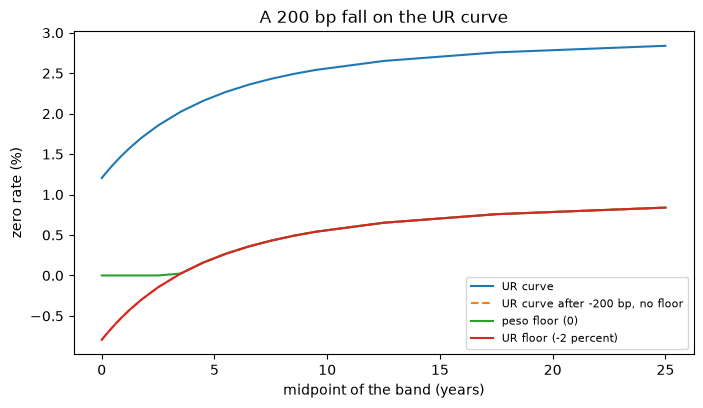

In [5]:
# Apply a 200 bp fall to the UR curve with the peso floor and with the UR floor and find where each binds
shape = np.full(19, -200.0)
raw = shocks.apply_floor(rates["UR"], shape, None)
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(MID, rates["UR"] * 100, label="UR curve")
ax.plot(MID, raw * 100, linestyle="--", label="UR curve after -200 bp, no floor")
for label, floor in (("peso floor (0)", 0.0), ("UR floor (-2 percent)", -0.02)):
    floored = shocks.apply_floor(rates["UR"], shape, floor)
    bound = [int(k) + 1 for k in np.flatnonzero(np.abs(floored - raw) > 1e-12)]
    print(f"{label:28s} bands where it binds: {bound}")
    ax.plot(MID, floored * 100, label=label)
print("lowest rate of the UR curve after -200 bp, before the floor:", round(float(raw.min()), 5))
ax.set_xlabel("midpoint of the band (years)")
ax.set_ylabel("zero rate (%)")
ax.set_title("A 200 bp fall on the UR curve")
ax.legend(fontsize=8)
plt.show()

The dashed line is the real curve after a 200 bp fall, with its short end at -0.795 percent. The peso floor lifts the first nine bands back to zero, the line that sits on the axis, and so would change a real-rate curve that has no reason to be non-negative; the UR floor of -2 percent lies below the whole shocked curve and binds in no band. That is why the floor has to be the currency's own: the peso floor applied to the UF would manufacture a loss in a currency whose rates were low but legitimately positive to begin with and negative after the shock. The figure shows one shock on one curve at one date and does not show that either floor binds in the committed variants, which the limit of BS-7 below says plainly.

**The offset and the charge.** The offset rule gives half credit to the gain leg when the two deltas have opposite signs. The `offset-on-off` variant holds the pair with and without the offset, and the same engine functions give the Annex measures both ways for the four variants. The charge is added once to the delta NII whatever the offset. The next cell prints both measures with and without the offset, the share of the delta NII that is the charge, and the closest approach of any post-shock rate to its floor, and draws the effect of the offset.

short-uf       ΔEVE     79,643     79,643
    ΔNII     11,067     14,597
    charge / ΔNII 0.5586 | closest floor (bp) 20.48
long-uf        ΔEVE     93,816     94,721
    ΔNII     11,213     14,597
    charge / ΔNII 0.5513 | closest floor (bp) 20.48
offset-on-off  ΔEVE     81,173     94,721
    ΔNII     11,016     14,597
    charge / ΔNII 0.5612 | closest floor (bp) 20.48
floors-active  ΔEVE     60,764     60,764
    ΔNII      6,606      7,528
    charge / ΔNII 0.1560 | closest floor (bp) 20.48


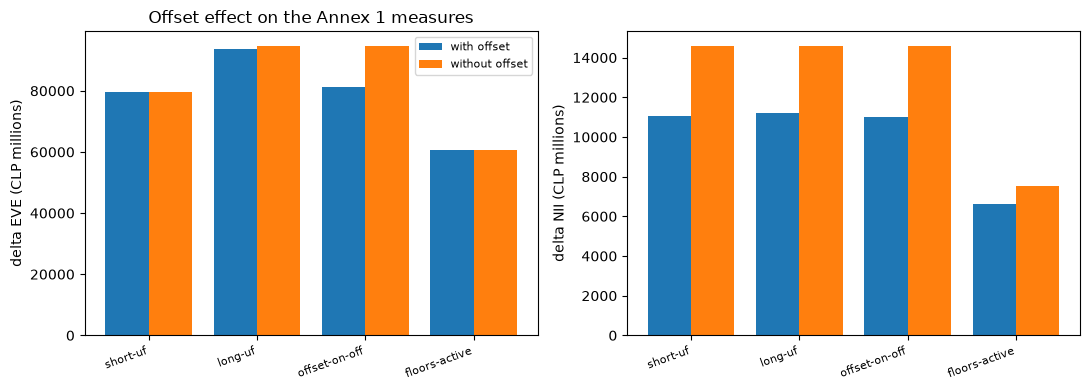

In [6]:
# The Annex measures with and without the offset, the charge as a share of the delta NII, and the closest floor
annex = {}
for v, d in variants.items():
    o = d["outputs"]
    d_clp, d_ur = (np.array([r["pair"][k] for r in o["eve"]["rows"]]) for k in ("delta_clp", "delta_ur"))
    n_clp, n_ur = (np.array([r["pair"][k] for r in o["nii"]["rows"]]) for k in ("delta_clp", "delta_ur"))
    eve_on, eve_off = (eve_nii.annex1_delta_eve(d_clp, d_ur, flag) for flag in (True, False))
    pn = o["indexation_charge"]["pn_ur"]
    nii_on, nii_off = (eve_nii.annex1_delta_nii(n_clp, n_ur, pn, flag) for flag in (True, False))
    closest = min(x["distance_bp"] for x in o["floors"]["distances"])
    annex[v] = (eve_on.delta_eve, nii_on.delta_nii, eve_off.delta_eve, nii_off.delta_nii)
    print(f"{v:14s} ΔEVE {eve_on.delta_eve:10,.0f} {eve_off.delta_eve:10,.0f}")
    print(f"    ΔNII {nii_on.delta_nii:10,.0f} {nii_off.delta_nii:10,.0f}")
    print(f"    charge / ΔNII {nii_on.indexation_charge / nii_on.delta_nii:.4f} | closest floor (bp) {closest:.2f}")
x = np.arange(len(annex))
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4))
panels = ((left, (0, 2), "delta EVE (CLP millions)"), (right, (1, 3), "delta NII (CLP millions)"))
for ax, (k_on, k_off), ylabel in panels:
    ax.bar(x - 0.2, [annex[v][k_on] for v in annex], 0.4, label="with offset")
    ax.bar(x + 0.2, [annex[v][k_off] for v in annex], 0.4, label="without offset")
    ax.set_xticks(x, list(annex), rotation=20, ha="right", fontsize=8)
    ax.set_ylabel(ylabel)
left.set_title("Offset effect on the Annex 1 measures")
left.legend(fontsize=8)
fig.tight_layout()
plt.show()

The offset acts mostly on the NII. In the short-UF variant it lowers the delta NII from 14,597 to 11,067, 24 percent, and in the offset-on-off variant it lowers the delta EVE from 94,721 to 81,173, 14 percent; in the short-UF variant it does not change the delta EVE because the worst shock has both legs losing. The charge is 55.9, 55.1 and 56.1 percent of the delta NII in the three variants with a net UF position of 30 percent of Tier 1, and 15.6 percent in the variant with 5 percent. The closest approach of any post-shock rate to its floor is 20.48 bp in all four. The figure shows the effect of one rule on four synthetic variants, not a statement about any real bank.

**The counterfactual: what a single-currency treatment loses.** Without the UR, a bank would put its UF flows, converted to pesos, with the peso flows, discount them all on the peso curve, shock them with the peso sizes and the zero floor, and add no charge: one currency. The cell does exactly that with the engine for the four variants, using the committed net flows of each leg, and compares the two measures and the ratios to Tier 1. It is a counterfactual, not a rival method: it shows what is lost when the UF is not a currency of its own. The difference has four parts that act together, the curve (nominal instead of real), the sizes (peso sizes for the UF flows), the full netting of the legs inside a single sum, and the missing charge.

In [7]:
# Annex 1 measures against a single-currency treatment of the same flows: peso curve, sizes and floor, no charge
peso = shocks.shock_size("CLP", "cmf-annex1")
single = {}
for v, d in variants.items():
    o = d["outputs"]
    uf = o["ur_currency"]["uf_value"]
    rows = {leg["leg"]: [r for item in leg["items"] for r in item["cash_flows"]] for leg in o["legs"]}
    vec = {k: np.bincount([r["bucket"] - 1 for r in rs], [r["amount"] for r in rs], 19) for k, rs in rows.items()}
    total = vec["CLP"] + uf * vec["UR"]
    r_peso = np.array(o["curves"]["clp"]["zero_rates_at_midpoints"])
    loss_eve = []
    for row in o["eve"]["rows"]:
        net = np.array(row["clp"]["net_cash_flows"]) + np.array(row["ur"]["net_cash_flows"])
        shape = shocks.shock_curve(row["shock"], peso.parallel_bp, peso.short_bp, peso.long_bp, MID)
        shocked = shocks.apply_floor(r_peso, shape, 0.0)
        loss_eve.append(eve_nii.delta_eve(total, net, r_peso, shocked, MID))
    flat = [shocks.apply_floor(r_peso, np.full(19, bp), 0.0) for bp in (300.0, -300.0)]
    loss_nii = [eve_nii.delta_nii(total, r_peso, shocked, MID) for shocked in flat]
    single[v] = (max(0.0, max(loss_eve)), max(0.0, max(loss_nii)))
    print(f"{v:14s} ΔEVE Annex 1 {annex[v][0]:10,.0f} | single currency {single[v][0]:10,.0f}")
    print(f"    ΔNII Annex 1 {annex[v][1]:10,.0f} | single currency {single[v][1]:10,.0f}")

short-uf       ΔEVE Annex 1     79,643 | single currency     64,213
    ΔNII Annex 1     11,067 | single currency      1,356
long-uf        ΔEVE Annex 1     93,816 | single currency     84,710
    ΔNII Annex 1     11,213 | single currency      1,648
offset-on-off  ΔEVE Annex 1     81,173 | single currency     59,422
    ΔNII Annex 1     11,016 | single currency      1,254
floors-active  ΔEVE Annex 1     60,764 | single currency     49,837
    ΔNII Annex 1      6,606 | single currency      4,653


The next cell draws the four measures of each variant as a share of Tier 1, with the 15 percent line of the EVE and the 5 percent line of the NII.

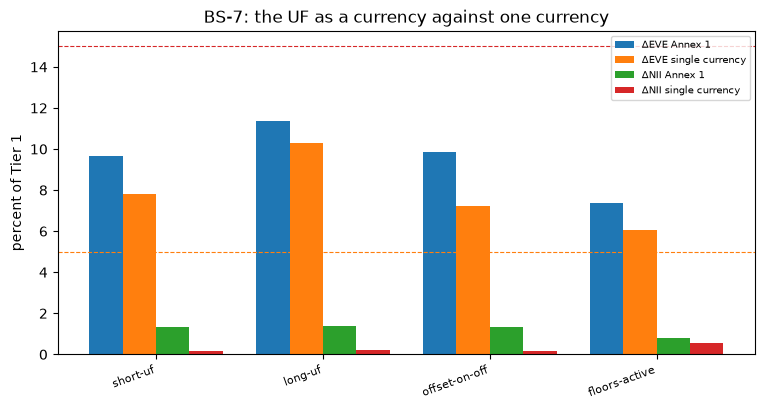

In [8]:
# Draw the Annex 1 measures and the single-currency counterfactual as a share of Tier 1
tier = {v: d["outputs"]["thresholds"]["tier1"] for v, d in variants.items()}
series = []
specs = [("ΔEVE Annex 1", annex, 0), ("ΔEVE single currency", single, 0)]
specs += [("ΔNII Annex 1", annex, 1), ("ΔNII single currency", single, 1)]
for label, source, k in specs:
    series.append((label, [source[v][k] / tier[v] for v in variants]))
x = np.arange(len(variants))
fig, ax = plt.subplots(figsize=(9, 4.2))
for k, (label, values) in enumerate(series):
    ax.bar(x + (k - 1.5) * 0.2, [100 * value for value in values], 0.2, label=label)
ax.axhline(15, color="tab:red", linestyle="--", linewidth=0.8)
ax.axhline(5, color="tab:orange", linestyle="--", linewidth=0.8)
ax.set_xticks(x, list(variants), rotation=20, ha="right", fontsize=8)
ax.set_ylabel("percent of Tier 1")
ax.set_title("BS-7: the UF as a currency against one currency")
ax.legend(fontsize=7)
plt.show()

Treating the UF flows as pesos gives a delta NII of 1,356, 1,648 and 1,254 for the short-UF, long-UF and offset-on-off variants against the Annex 1 values of 11,067, 11,213 and 11,016: 6.8 to 8.8 times smaller, because the single-currency sum has no charge and lets the legs net out fully. The delta EVE is 64,213, 84,710 and 59,422 against 79,643, 93,816 and 81,173: 10 to 27 percent smaller. In the floors-active variant, with a net UF position of 5 percent of Tier 1, the gap is smaller, 4,653 against 6,606 for the NII. In these four variants no ratio crosses its line under either treatment, so the claim is not that a bank would pass or fail differently but that the measure the regulator defines is not the one a single-currency calculation gives.

**The limit of BS-7.** The evidence shows that the engine implements Annex 1 as a separate currency and that the committed variants recompute from it. It does not show that the Annex is applied the way the CMF applies it: there is no second implementation to reconcile with, and the dossier's search found none (UNVERIFIED beyond that search). The floors are implemented and tested but never bind on the committed curves, the closest being 20.48 bp away, so their effect on a number is not demonstrated by this data. The bank is synthetic. And the claim is regional: the standard has no UF-like unit, and only Chile's Annex needs one here.

### BS-8: a test that flags a behavioural assumption changed at a limit breach

**What the claim adds.** `irrbb.behavioural_change_at_breach` takes the series of a behavioural parameter, the dates and a breach flag per date, and counts the dates where the parameter changed and the flag is true. It is red at one or more, green at none, and `not_evaluated` with fewer than two dates. The first cell shows that the test discriminates, on five constructed histories whose answer is known: a parameter held fixed through a breach, a parameter that changes with no breach, a parameter changed at a breach, a parameter changed before the breach but not at it, and a single date. These are constructed numbers that exercise the rule, not data of any bank.

fixed through a breach       [4.0, 4.0, 4.0] ['yes', 'yes', 'yes']
    green | flagged dates: []
changed, no breach           [4.0, 4.5, 5.0] ['no', 'no', 'no']
    green | flagged dates: []
changed at a breach          [4.0, 4.0, 4.5] ['no', 'no', 'yes']
    red | flagged dates: ['2022-12-31']
changed before the breach    [4.0, 4.5, 4.5] ['no', 'no', 'yes']
    green | flagged dates: []
a single date                [4.0] ['yes']
    not evaluated | flagged dates: []


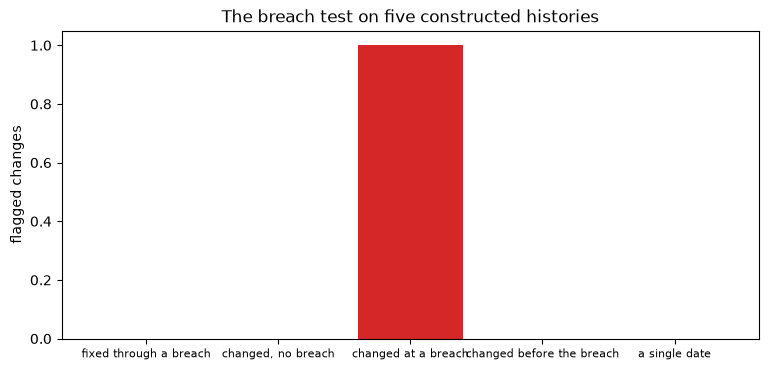

In [9]:
# Five constructed histories with a known answer: fixed, changed with no breach, changed at or before a breach
days = np.array(["2021-12-31", "2022-06-30", "2022-12-31"], dtype="datetime64[D]")
cases = [
    ("fixed through a breach", [4.0, 4.0, 4.0], [True, True, True], days),
    ("changed, no breach", [4.0, 4.5, 5.0], [False, False, False], days),
    ("changed at a breach", [4.0, 4.0, 4.5], [False, False, True], days),
    ("changed before the breach", [4.0, 4.5, 4.5], [False, False, True], days),
    ("a single date", [4.0], [True], days[:1]),
]
results = []
for label, values, flags, when in cases:
    run = rv_irrbb.behavioural_change_at_breach(np.array(values), when, np.array(flags, dtype=bool))
    results.append(run)
    print(f"{label:28s} {values} {[NAME[f] for f in flags]}")
    print(f"    {LIGHT[run.light.value]} | flagged dates: {run.extras.get('flagged_dates', [])}")
tint = {"green": "tab:green", "red": "tab:red", "not_evaluated": "lightgrey"}
fig, ax = plt.subplots(figsize=(9, 4))
counts = [np.nan_to_num(run.statistic) for run in results]
ax.bar([c[0] for c in cases], counts, color=[tint[run.light.value] for run in results])
ax.set_ylabel("flagged changes")
ax.set_title("The breach test on five constructed histories")
ax.tick_params(axis="x", labelsize=8)
plt.show()

Only the third history is red, the parameter that moves from 4.0 to 4.5 at the date where the limit is breached, and the test names that date, 2022-12-31. The parameter held fixed through a breach is green, so a breach alone does not trigger it; the parameter that changes with no breach is green, so a change alone does not either; and the parameter that changed before the breach and then held is green, because the change did not coincide with it. A single date cannot be compared and the test says so instead of returning a number. These are constructed numbers that exercise the rule: they show the test discriminates, not that anyone has done what the third history does.

**The evidence on the committed bank.** The committed model document lists, for two consecutive pairs of dates, the behavioural parameters of the wholesale deposits and whether each changed: the core share and the core maturity that Contraste requests (stated, synthetic) and the weighted average maturity of the fitted replicating portfolio. The cell runs the engine test on the three series of the three dates with the breach flag of each date from the committed scenarios, and prints the flagged dates. Then it runs the same test on the average maturity with the breach flags all set to false, as a control: the verdict is decided by the flag, not by the movement alone.

dates: ['2021-12-31', '2022-06-30', '2022-12-31'] | breach flags: ['yes', 'yes', 'yes']
requested core share               [0.6, 0.6, 0.6]
    green | flagged dates: []
requested core maturity (y)        [5.0, 5.0, 5.0]
    green | flagged dates: []
fitted average maturity (y)        [4.7595, 4.2049, 5.0]
    red | flagged dates: ['2022-06-30', '2022-12-31']
control: the fitted maturity with no breach -> green


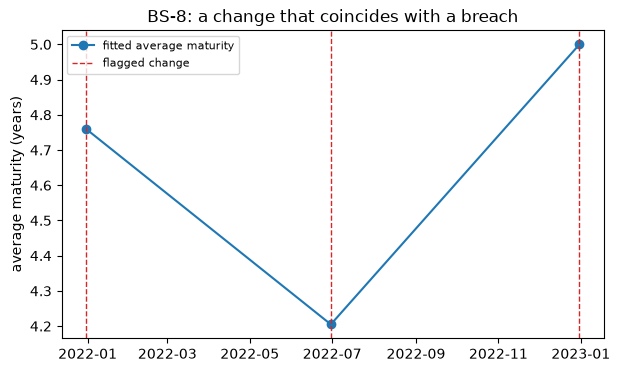

In [10]:
# Run the breach test on three parameters of the wholesale deposits at the three dates, and a control
dates = np.array([d["outputs"]["valuation_date"] for d in docs.values()], dtype="datetime64[D]")
breach = np.array([bool(d["outputs"]["scenarios"][0]["outlier"]["breached"]) for d in docs.values()])
wholesale = [next(s for s in d["outputs"]["nmd_segments"] if s["category"] == "wholesale") for d in docs.values()]
by_date = {m["valuation_date"]: m["weighted_average_maturity_years"] for m in fit["nmd_models"]}
wam = [by_date[str(day)] for day in dates]
series = {"requested core share": [s["requested_core_share"] for s in wholesale]}
series["requested core maturity (y)"] = [s["requested_core_maturity_years"] for s in wholesale]
series["fitted average maturity (y)"] = wam
print("dates:", [str(x) for x in dates], "| breach flags:", [NAME[bool(b)] for b in breach])
for name, values in series.items():
    run = rv_irrbb.behavioural_change_at_breach(np.array(values), dates, breach)
    print(f"{name:34s} {[round(v, 4) for v in values]}")
    print(f"    {LIGHT[run.light.value]} | flagged dates: {run.extras['flagged_dates']}")
control = rv_irrbb.behavioural_change_at_breach(np.array(wam), dates, np.zeros(3, dtype=bool))
print("control: the fitted maturity with no breach ->", LIGHT[control.light.value])
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(dates, wam, marker="o", color="tab:blue", label="fitted average maturity")
for day in run.extras["flagged_dates"]:
    ax.axvline(np.datetime64(day), color="tab:red", linestyle="--", linewidth=1)
ax.axvline(dates[0], color="tab:red", linestyle="--", linewidth=1, label="flagged change")
ax.set_ylabel("average maturity (years)")
ax.set_title("BS-8: a change that coincides with a breach")
ax.legend(fontsize=8)
plt.show()

Two of the three parameters do not move: the share of the stable deposits that Contraste requests stays at 0.6 and its maturity at 5 years, and the test is green for both although the limit is breached at every date. The fitted average maturity does move, 4.7595, 4.2049 and 5.0 years, and the test is red at 2022-06-30 and 2022-12-31, the dates of the dashed lines; with the breach flags set to false the same series is green, so the flag decides the verdict. The figure shows that the test operates on the committed parameters. It does not show that anyone tuned the fitted maturity: it is re-estimated at each date and so differs by construction.

**The limit of BS-8.** The red row is not a finding about the bank. In C14 the bank's outlier test is breached at the three dates, so the breach flag never varies; the parameter that moves is the fitted replicating-portfolio maturity, which is re-estimated at each date and therefore differs by construction, while the two parameters Contraste states are held fixed and are not flagged. What the evidence shows is that the test separates a stated assumption held through a breach from a series that moves while the limit is breached, and that its verdict is decided by the breach flag; the same series with no breach is green. It does not show that anyone chose the fitted maturity to relieve a breach, and the bank's behaviour is synthetic. A red is a prompt for the validator to ask who moved the parameter, when, why, and with what approval, and whether the new value is supported by the data; the first answers are in the model-governance record, not in the test.

## Results

**Answer:** yes to both, with limits. Treating the UF flows as pesos gives a delta NII of 1,356 for the short-UF variant against the Annex 1 value of 11,067, and a delta EVE of 64,213 against 79,643, so the measure of the regulator is not the one a single-currency calculation gives. The breach test flags the fitted average maturity of the wholesale deposits at 2022-06-30 and 2022-12-31, while the requested core share (0.6) and maturity (5 years) are green and the same fitted series with no breach is green: the breach flag decides.

- **BS-7, the separation.** Neither Basel table has the peso or the UF (21 currencies each), and the engine refuses a size for them. The Chilean table gives the peso 300/400/200 bp and the UR 200/250/150 bp for the EVE and 300 bp for the NII, and each currency is on its own curve: 0.04499 in the first band for the peso and 0.01205 for the UR. The floor has to be the currency's own: a 200 bp fall takes the UR curve to -0.00795 in the first band, and the peso floor of 0 would bind in nine bands while the UR floor of -2 percent binds in none.
- **BS-7, what a single currency loses.** The delta NII is 1,356, 1,648 and 1,254 against 11,067, 11,213 and 11,016 for the short-UF, long-UF and offset-on-off variants: 6.8 to 8.8 times smaller. The delta EVE is 64,213, 84,710 and 59,422 against 79,643, 93,816 and 81,173: 10 to 27 percent smaller. No ratio to Tier 1 crosses a line in either treatment in these four variants.
- **BS-7, the offset and the charge.** The offset lowers the delta NII from 14,597 to 11,067 in the short-UF variant and the delta EVE from 94,721 to 81,173 in the offset-on-off variant. The charge is 0.5586, 0.5513 and 0.5612 of the delta NII in the three variants with a net UF position of 30 percent of Tier 1, and 0.1560 in the one with 5 percent.
- **BS-7, the limit.** The floors never bind: the closest post-shock rate is 20.48 bp from its floor in the four variants, so their effect on a number is not demonstrated here. There is no second implementation of Annex 1 to reconcile with; the dossier's search found none, which stays unverified beyond it. The bank is synthetic, and the claim is regional.
- **BS-8, the discrimination.** On the five constructed histories the test gives the verdict the rule says: green for a parameter held fixed through a breach, green for a change with no breach, green for a change before the breach, red for a change at the breach (flagging 2022-12-31), and not evaluated for a single date.
- **BS-8, the committed bank.** The requested core share (0.6) and the requested core maturity (5.0 years) do not change and the test is green; the fitted average maturity moves, 4.7595, 4.2049 and 5.0 years, and the test is red at 2022-06-30 and 2022-12-31. With the breach flags set to false the same series is green.
- **BS-8, the limit.** The outlier test is breached at the three dates, so the flag never varies, and the parameter that moves is a fitted one that is re-estimated at each date, so it differs by construction. The red is therefore not a finding that anyone tuned the maturity to relieve a breach; it shows that the test operates on those parameters and would do so on a parameter that a manager changed. What a validator does with a red: ask who moved the parameter, when and with what approval; compare the new value with the data that support it (notebook 05 shows that the fitted weights are not stable across windows); and read the EVE with and without behaviour at the same date. The bank's behaviour is synthetic.
- **What the notebook does not show.** A reconciliation of the Chilean figures with a second implementation, the effect of a floor on a number, and a case where a manager changed a stated assumption at a breach: the committed data has none.

## Summary

- BS-7: the Chilean Annex treats the UF as a currency of its own; the engine implements its sizes, floor, offset and charge, and the committed variants recompute from it. A single-currency treatment of the same flows would give a very different delta NII, because the charge and the pairing are what make the NII measure.
- BS-7 has limits: no second implementation to reconcile with, floors that never bind on these curves, a synthetic bank, and a regional claim.
- BS-8: the breach test is red when a parameter changes at a date with a breach and green otherwise, and the verdict is decided by the breach flag.
- BS-8 has limits: in the committed bank every date is a breach and the parameter that moves is a fitted one, so the red shows that the test operates, not that the bank did what the review of the failed bank found.
- Both claims are stated in the SDD only as far as this evidence goes.

**What to try next.** Change the breach flags of the constructed histories and write down which verdict follows which rule. Then read the claims in the SDD's section `## Beyond the state of the art` against this notebook.

## References

- CMF, Recopilacion Actualizada de Normas, chapter 21-13, Annex 1 (the UR, the sizes, the floors, the offset and the charge). https://www.cmfchile.cl/portal/principal/623/articles-29808_doc_pdf.pdf
- BCBS, Standards: Interest rate risk in the banking book, SRP31.90 (the shock sizes) and SRP31.129. https://www.bis.org/basel_framework/chapter/SRP/31.htm
- BCBS (2024), d578, Recalibration of shocks for interest rate risk in the banking book. https://www.bis.org/publications/202407-standards-recalibration-shocks-interest-rate-risk-banking-book.pdf
- Board of Governors of the Federal Reserve System (2023), Review of the Federal Reserve's Supervision and Regulation of Silicon Valley Bank. https://www.federalreserve.gov/publications/files/svb-review-20230428.pdf
- CMF, Informe del Desempeno del Sistema Bancario y Cooperativas, August 2026. https://www.cmfchile.cl/portal/estadisticas/617/articles-113863_recurso_1.pdf
- FDIC, BankFind financials, public domain. https://api.fdic.gov/banks/financials
- US Department of the Treasury, Daily Treasury Par Yield Curve Rates, public domain. https://home.treasury.gov/resource-center/data-chart-center/interest-rates
- Dossier 03 (Chile, section F.2) and dossier 05 (section D.7) of the Contraste research; the SDD section `## Beyond the state of the art`.